# 04 — LightGBM dan perbandingan model

Gunakan numerik dan kategori native sebelum seleksi IV baseline. Pilih konfigurasi melalui
**10 trial Optuna × 5-fold CV** pada training, lalu evaluasi sekali pada test yang sama dengan baseline.
Perbandingan ini mencakup keseluruhan pipeline preprocessing dan model, bukan algoritma semata.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from src.config import ID_COL, TARGET_COL, CORE_RAW_FILES, PROCESSED_DATA_DIR, MODELS_DIR, RANDOM_SEED, N_FOLDS
from src.data import load_raw_tables, build_master_table, split_application_ids

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 15)

import hashlib
import importlib.metadata
import json
import joblib
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from src.modeling import WOETransformer, NativeCategoricalTransformer, model_feature_columns
from src.evaluation import evaluation_summary, plot_diagnostics

VERSIONS = {p: importlib.metadata.version(p) for p in
            ["numpy", "pandas", "scikit-learn", "optbinning", "lightgbm", "optuna", "pyarrow"]}
display(pd.Series(VERSIONS, name="Versi lingkungan").to_frame())

import lightgbm as lgb
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)


,Versi lingkungan
numpy,2.5.0
pandas,3.0.3
scikit-learn,1.9.0
optbinning,0.21.0
lightgbm,4.6.0
optuna,4.9.0
pyarrow,24.0.0


C:\Users\muhammad.perdana\AppData\Local\anaconda3\envs\credit-risk\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Muat data dan hasil baseline

In [2]:
master = pd.read_parquet(PROCESSED_DATA_DIR / "master_table.parquet")
manifest_path = PROCESSED_DATA_DIR / "split_manifest.csv"
manifest = pd.read_csv(manifest_path)
pd.testing.assert_frame_equal(manifest, split_application_ids(master))
split_hash = hashlib.sha256(manifest_path.read_bytes()).hexdigest()
feature_cols = model_feature_columns(master)
assert not {ID_COL, TARGET_COL, "DAYS_BIRTH", "DAYS_EMPLOYED"}.intersection(feature_cols)
indexed = master.set_index(ID_COL)
train_ids = manifest.loc[manifest["split"].eq("train"), ID_COL].to_numpy()
test_ids = manifest.loc[manifest["split"].eq("test"), ID_COL].to_numpy()
assert set(train_ids).isdisjoint(test_ids)
X_train, y_train = indexed.loc[train_ids, feature_cols], indexed.loc[train_ids, TARGET_COL]
X_test, y_test = indexed.loc[test_ids, feature_cols], indexed.loc[test_ids, TARGET_COL]
folds = list(StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_SEED).split(X_train, y_train))
print(f"Training: {X_train.shape}; test dikunci: {X_test.shape}")
print(f"Kandidat kategorikal: {sum(not pd.api.types.is_numeric_dtype(X_train[c]) for c in feature_cols)}")
print(f"Prevalensi target training: {y_train.mean():.4%}")

baseline_metadata = json.loads((PROCESSED_DATA_DIR / "baseline_metrics.json").read_text(encoding="utf-8"))
assert baseline_metadata["split_sha256"] == split_hash
baseline_predictions = pd.read_parquet(PROCESSED_DATA_DIR / "baseline_test_predictions.parquet").set_index(ID_COL)
assert baseline_predictions.index.is_unique
assert set(baseline_predictions.index) == set(test_ids)
baseline_predictions = baseline_predictions.loc[test_ids]
np.testing.assert_array_equal(baseline_predictions[TARGET_COL].to_numpy(), y_test.to_numpy())
baseline_test_metrics = evaluation_summary(y_test, baseline_predictions["probability"])
np.testing.assert_allclose(baseline_test_metrics.reindex(baseline_metadata["test_metrics"]).to_numpy(),
                           list(baseline_metadata["test_metrics"].values()))


Training: (246008, 176); test dikunci: (61503, 176)
Kandidat kategorikal: 16
Prevalensi target training: 8.0729%


## 2. Tuning pada training saja

Daftar kategori dipelajari ulang di setiap training fold. Kategori baru menjadi missing, sedangkan
NaN numerik ditangani native. Placeholder kategori sumber dipertahankan.

Sampler TPE memakai seed 42. `subsample_freq=1` mengaktifkan row sampling; weighting merupakan
pilihan trial dan rasio kelas dihitung dari training fold. Objective menggunakan ROC-AUC mentah.
Early stopping 30 ronde memakai validation fold. Mean CV trial terbaik adalah skor seleksi,
sehingga tetap dapat optimistis setelah tuning; test dilaporkan terpisah.

In [3]:
from sklearn.metrics import roc_auc_score

def objective(trial):
    params = {
        "objective": "binary", "metric": "auc", "verbosity": -1,
        "random_state": RANDOM_SEED, "n_jobs": 4, "subsample_freq": 1,
        "num_leaves": trial.suggest_int("num_leaves", 16, 64),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "learning_rate": trial.suggest_float("learning_rate", .01, .1, log=True),
        "n_estimators": trial.suggest_int("n_estimators", 100, 500),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 100),
        "subsample": trial.suggest_float("subsample", .6, 1.),
        "colsample_bytree": trial.suggest_float("colsample_bytree", .6, 1.),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10., log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10., log=True),
    }
    weighted = trial.suggest_categorical("use_weighting", [False, True])
    scores, iterations, rows = [], [], []
    for fold, (tr, va) in enumerate(folds, start=1):
        X_tr, X_val = X_train.iloc[tr], X_train.iloc[va]
        y_tr, y_val = y_train.iloc[tr], y_train.iloc[va]
        encoder = NativeCategoricalTransformer()
        native_train = encoder.fit_transform(X_tr, y_tr)
        native_val = encoder.transform(X_val)
        assert set(encoder.fit_index_) == set(X_tr.index)
        assert set(encoder.fit_index_).isdisjoint(X_val.index)
        assert set(encoder.fit_index_).isdisjoint(test_ids)
        weight = float(y_tr.eq(0).sum() / y_tr.eq(1).sum()) if weighted else 1.
        model = lgb.LGBMClassifier(**params, scale_pos_weight=weight)
        model.fit(native_train, y_tr, eval_set=[(native_val, y_val)],
                  callbacks=[lgb.early_stopping(30, verbose=False)])
        probabilities = model.predict_proba(native_val)[:, 1]
        scores.append(float(roc_auc_score(y_val, probabilities)))
        iterations.append(int(model.best_iteration_))
        rows.append({"fold": fold, "n_features": native_train.shape[1],
                     "scale_pos_weight": weight, **evaluation_summary(y_val, probabilities).to_dict()})
    trial.set_user_attr("best_iterations", iterations)
    trial.set_user_attr("fold_metrics", rows)
    print(f"Trial {trial.number + 1}/10: AUC={np.mean(scores):.6f}; iterasi={iterations}; weighted={weighted}")
    return float(np.mean(scores))

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_SEED))
study.optimize(objective, n_trials=10, n_jobs=1)
study.trials_dataframe().to_csv(PROCESSED_DATA_DIR / "lightgbm_trials.csv", index=False)
best_trial = study.best_trial
cv_results = pd.DataFrame(best_trial.user_attrs["fold_metrics"])
cv_results.to_csv(PROCESSED_DATA_DIR / "lightgbm_cv.csv", index=False)
display(cv_results.round(6))
print("Best params:", study.best_params)
print(f"CV AUC terpilih: {cv_results.AUC.mean():.6f} ± {cv_results.AUC.std():.6f}")


Trial 1/10: AUC=0.767892; iterasi=[334, 292, 332, 338, 198]; weighted=False


Trial 2/10: AUC=0.755128; iterasi=[172, 172, 172, 172, 172]; weighted=False


Trial 3/10: AUC=0.766137; iterasi=[413, 413, 414, 414, 405]; weighted=False


Trial 4/10: AUC=0.764078; iterasi=[134, 179, 166, 142, 127]; weighted=True


Trial 5/10: AUC=0.762608; iterasi=[308, 308, 308, 308, 307]; weighted=False


...

Trial 8/10: AUC=0.759036; iterasi=[446, 446, 446, 446, 446]; weighted=False


Trial 9/10: AUC=0.760851; iterasi=[386, 386, 386, 386, 386]; weighted=False


Trial 10/10: AUC=0.757236; iterasi=[226, 226, 226, 226, 226]; weighted=False


,fold,n_features,scale_pos_weight,AUC,Gini,KS,AP,Brier,LogLoss
0,1,176,1.0,0.766433,0.532867,39.942392,0.244214,0.067711,0.244519
1,2,176,1.0,0.768288,0.536577,40.817313,0.259949,0.067021,0.242795
2,3,175,1.0,0.766855,0.533710,40.246970,0.251932,0.067337,0.243601
3,4,176,1.0,0.769223,0.538447,40.023009,0.247373,0.067517,0.243621
4,5,175,1.0,0.768661,0.537321,40.596755,0.250138,0.067390,0.243559


Best params: {'num_leaves': 34, 'max_depth': 10, 'learning_rate': 0.05395030966670229, 'n_estimators': 340, 'min_child_samples': 24, 'subsample': 0.662397808134481, 'colsample_bytree': 0.6232334448672797, 'reg_alpha': 2.9154431891537547, 'reg_lambda': 0.2537815508265665, 'use_weighting': False}
CV AUC terpilih: 0.767892 ± 0.001196


## 3. Refit dengan median best iteration

In [4]:
best_params = study.best_params.copy()
weighted = best_params.pop("use_weighting")
best_params["n_estimators"] = int(np.median(best_trial.user_attrs["best_iterations"]))
best_params.update({"objective": "binary", "metric": "auc", "verbosity": -1,
    "random_state": RANDOM_SEED, "n_jobs": 4, "subsample_freq": 1,
    "scale_pos_weight": float(y_train.eq(0).sum() / y_train.eq(1).sum()) if weighted else 1.})
pipeline = Pipeline([("preprocess", NativeCategoricalTransformer()),
                     ("model", lgb.LGBMClassifier(**best_params))])
pipeline.fit(X_train, y_train)
encoder = pipeline.named_steps["preprocess"]
assert set(encoder.fit_index_) == set(train_ids)
assert set(encoder.fit_index_).isdisjoint(test_ids)
print("Final boosting rounds:", best_params["n_estimators"])
print("Fitur final:", len(encoder.feature_names_in_), "; kategorikal:", len(encoder.categories_))


Final boosting rounds: 332
Fitur final: 176 ; kategorikal: 16


## 4. Evaluasi akhir dan perbandingan pada ID test identik

,Train LightGBM,Test LightGBM
AUC,0.838064,0.771327
Gini,0.676127,0.542653
KS,51.615131,40.599576
AP,0.369920,0.263860
Brier,0.062032,0.066886
LogLoss,0.220573,0.241959


,AUC,Gini,KS,AP,Brier,LogLoss,CV_AUC_mean,CV_AUC_std,n_features
LR + WOE,0.741800,0.483601,36.249294,0.220742,0.205430,0.597358,0.738812,0.001286,37
LightGBM,0.771327,0.542653,40.599576,0.263860,0.066886,0.241959,0.767892,0.001196,176


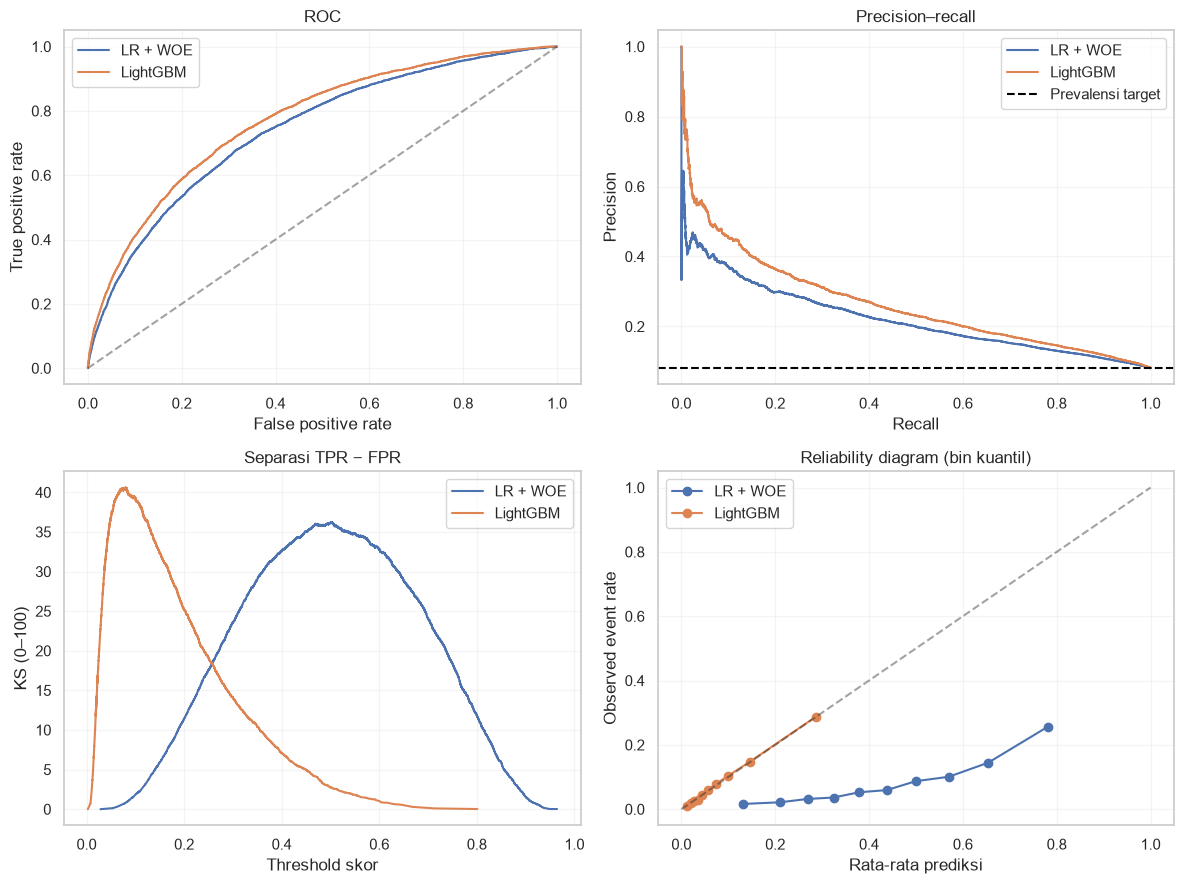

In [5]:
p_train = pipeline.predict_proba(X_train)[:, 1]
p_test = pipeline.predict_proba(X_test)[:, 1]
metrics_train = evaluation_summary(y_train, p_train)
metrics_test = evaluation_summary(y_test, p_test)
display(pd.DataFrame({"Train LightGBM": metrics_train, "Test LightGBM": metrics_test}).round(6))
comparison = pd.DataFrame({"LR + WOE": baseline_test_metrics, "LightGBM": metrics_test}).T
comparison["CV_AUC_mean"] = [baseline_metadata["cv_auc_mean"], cv_results.AUC.mean()]
comparison["CV_AUC_std"] = [baseline_metadata["cv_auc_std"], cv_results.AUC.std()]
comparison["n_features"] = [baseline_metadata["n_features"], len(encoder.feature_names_in_)]
display(comparison.round(6))
comparison.to_csv(PROCESSED_DATA_DIR / "model_comparison.csv")
plot_diagnostics(y_test, {"LR + WOE": baseline_predictions["probability"].to_numpy(), "LightGBM": p_test})
plt.show()


ROC-AUC/AP lebih tinggi berarti ranking lebih baik; Brier/log loss lebih rendah lebih baik.
Gini merupakan transformasi AUC. Reliability diagram membandingkan rata-rata prediksi dengan
observed event rate, bukan membuktikan kalibrasi di populasi baru. Class weighting dapat
mengubah estimasi probabilitas. Tidak ada kalibrator atau cutoff kebijakan pada tahap ini.

## 5. Native feature importance

,feature,gain
39,EXT_SOURCE_3,38300.757094
38,EXT_SOURCE_2,33885.452843
36,ORGANIZATION_TYPE,16597.217995
129,CREDIT_TO_ANNUITY_RATIO,13375.354398
37,EXT_SOURCE_1,11936.153469
24,OCCUPATION_TYPE,5883.464447
132,AGE_YEARS,5712.468885
131,EMPLOYMENT_LENGTH_YEARS,4327.444755
125,prev_amt_annuity_mean,4233.737626
124,prev_amt_credit_mean,3959.289049


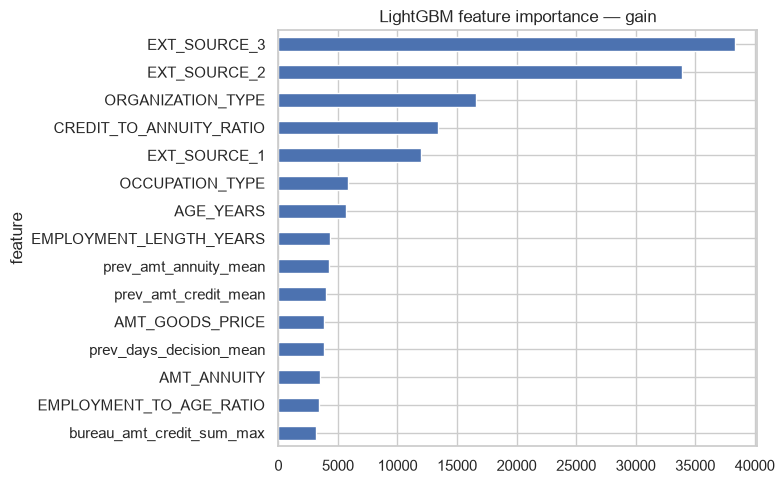

In [6]:
importance = pd.DataFrame({"feature": encoder.feature_names_in_,
    "gain": pipeline.named_steps["model"].booster_.feature_importance(importance_type="gain")})
importance = importance.sort_values("gain", ascending=False)
display(importance.head(15))
importance.head(15).set_index("feature").sort_values("gain").plot.barh(figsize=(8, 5), legend=False)
plt.title("LightGBM feature importance — gain")
plt.tight_layout()
plt.show()


Gain menunjukkan perbaikan objective dari split training, bukan efek kausal atau penjelasan
prediksi individual. Fitur berkorelasi dapat saling membagi importance. Interpretasi SHAP
belum termasuk pekerjaan notebook ini.

## 6. Simpan model, prediksi, dan kesimpulan aktual

In [7]:
metadata = {
    "model": "LightGBM", "seed": RANDOM_SEED, "split_sha256": split_hash,
    "cv_auc_mean": float(cv_results.AUC.mean()), "cv_auc_std": float(cv_results.AUC.std()),
    "use_weighting": weighted, "n_trials": len(study.trials),
    "fold_best_iterations": best_trial.user_attrs["best_iterations"],
    "n_features": len(encoder.feature_names_in_), "best_params": best_params,
    "train_metrics": metrics_train.to_dict(), "test_metrics": metrics_test.to_dict(),
    "versions": VERSIONS, "calibrated": False,
}
artifact = {"pipeline": pipeline, "feature_columns": feature_cols,
    "selected_features": encoder.feature_names_in_.tolist(), "categories": encoder.categories_,
    "model_params": pipeline.named_steps["model"].get_params(),
    "split_manifest": manifest, "metadata": metadata}
model_path = MODELS_DIR / "lightgbm_final.joblib"
joblib.dump(artifact, model_path)
np.testing.assert_allclose(joblib.load(model_path)["pipeline"].predict_proba(X_test)[:, 1], p_test,
                           rtol=1e-12, atol=1e-12)
pd.DataFrame({ID_COL: test_ids, TARGET_COL: y_test.to_numpy(), "probability": p_test}).to_parquet(
    PROCESSED_DATA_DIR / "lightgbm_test_predictions.parquet", index=False)
(PROCESSED_DATA_DIR / "lightgbm_metrics.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
auc_gap = metrics_test["AUC"] - baseline_test_metrics["AUC"]
ap_gap = metrics_test["AP"] - baseline_test_metrics["AP"]
display(Markdown(f"Selisih LightGBM − baseline pada test: **ROC-AUC {auc_gap:+.4f}**, "
    f"**AP {ap_gap:+.4f}**. LightGBM memakai **{metadata['n_features']} fitur**, "
    f"baseline **{baseline_metadata['n_features']} fitur**. "
    "Perbedaan ini deskriptif, belum diuji dengan interval ketidakpastian. "
    "Keputusan produksi tidak dapat ditentukan dari ranking saja; lihat pula reliability diagram, "
    "Brier/log loss, kebutuhan interpretasi, dan validasi pada populasi baru."))
print("Artefak kedua model, CV, prediksi, dan tabel perbandingan telah tersimpan.")


Selisih LightGBM − baseline pada test: **ROC-AUC +0.0295**, **AP +0.0431**. LightGBM memakai **176 fitur**, baseline **37 fitur**. Perbedaan ini deskriptif, belum diuji dengan interval ketidakpastian. Keputusan produksi tidak dapat ditentukan dari ranking saja; lihat pula reliability diagram, Brier/log loss, kebutuhan interpretasi, dan validasi pada populasi baru.

Artefak kedua model, CV, prediksi, dan tabel perbandingan telah tersimpan.


## Batas tahap ini

Test yang sama pernah dilihat pada eksperimen sebelumnya. Hasil merupakan evaluasi internal,
bukan validasi temporal/eksternal, dan output belum diklaim sebagai PD terkalibrasi.
Belum ada keputusan approval, estimasi laba, kalibrasi ulang, atau SHAP. Notebook 05–06 tetap rencana;
pekerjaan tahap ini berhenti pada perbandingan model yang dapat dijalankan ulang.

**Gap generalisasi aktual:** ROC-AUC train 0.8381 versus test 0.7713, selisih 0.0667. Mean CV 0.7679 relatif dekat dengan test, tetapi gap train–test tetap menunjukkan optimisme in-sample yang perlu diperhatikan. Model tidak diklaim bebas overfitting; konfigurasi tidak diubah berdasarkan hasil test.